# 05 Exploratory analysis of the SIMULATED delay data (medium scenario)

**Everything here is SIMULATED.** The data comes from the delay simulator on the Corridor B timetable, not from real delays, and every figure carries the label. Findings may reflect simulator design (headway, trains running daily, one lane per direction, random freight) rather than how a real railway behaves; each finding in `reports/phase4_findings.md` says how likely that is.

**What may be used.** Only what real data would contain: arrival and departure delays and times, the weather state, and the timetable. The cause labels, `delay_attribution`, the events table, the queue log and the ground-truth cascades are never read (a test checks this).

**Windows (configs/splits.yaml).**
* **Decision window: 2024-01-01 .. 2024-10-31** (fold 1's training range). Every analysis that informs modelling decisions uses only this.
* Descriptive window: 2024-01-01 .. 2025-08-31 (the training window). Data after 2024-10-31 appears **only in clearly marked descriptive plots**; in particular fold 1's validation data (Nov-Dec 2024) makes no decision.
* Validation fold 2 (Sep-Oct 2025) and the test window (Nov-Dec 2025) are never loaded.
* The simulated data covers calendar 2024 and 2025 (not earlier), and 2024 and 2025 share the same timetable.

In [1]:
import os, sys, time, warnings
os.chdir("..") if os.path.basename(os.getcwd()) == "notebooks" else None
sys.path.insert(0, ".")
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import splits
from src.analysis import eda
from src.graph.station_graph import build_station_tables

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
BLUE, ORANGE, GREEN, GREY, RED = "#1f6f9f", "#d98c1f", "#6a9f58", "#888888", "#b5483a"
FIG = Path("reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
def save(fig, name):
    fig.savefig(FIG / f"eda_{name}.png", dpi=130, bbox_inches="tight"); plt.show()
S = "  [SIMULATED]"
DEC, DESC = splits.eda_windows()["decision"], splits.eda_windows()["descriptive"]
print("decision window", DEC, "| descriptive window", DESC)
t0 = time.time()
from src.graph.timetable import load_timetable
tt = load_timetable()
nodes, edges, _ = build_station_tables(tt)
df, tt, nodes, bounds = eda.load_window(*DEC, tt=tt, nodes=nodes)
a = eda.arrivals(df, bounds)
lo, hi = bounds; n_nodes = len(nodes); n_hours = int((hi - lo) // 60)
km = nodes.set_index("node").km_from_new_delhi
print(f"{len(df):,} rows, {len(a):,} arrivals, {a.run_id.nunique():,} runs, {n_hours} hours in the decision window ({time.time() - t0:.0f}s)")
print("columns in memory:", list(df.columns))

decision window ('2024-01-01', '2024-10-31') | descriptive window ('2024-01-01', '2025-08-31')


4,738,118 rows, 4,639,065 arrivals, 68,625 runs, 7320 hours in the decision window (31s)
columns in memory: ['train', 'date', 'seq', 'station', 'scheduled_arrival', 'scheduled_departure', 'actual_arrival', 'actual_departure', 'arrival_delay', 'departure_delay', 'abs_arr', 'abs_dep', 'run_id', 'node', 'prev_node', 'prev_dep_delay', 'first_in_visit', 'direction', 'type', 'sched_hour', 'H', 'arr_date', 'month', 'dow', 'weather', 'season']


## 1. Delay distributions (decision window)

arrival delay (min): mean 11.6 | median 0.2 | p90 35.1 | p95 58.4 | p99 130.7 | max 498
share <=5 min 0.660 | <=10 min 0.728 | >30 min 0.120 | >60 min 0.048


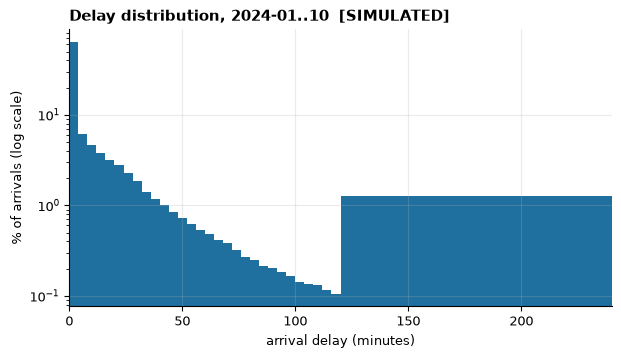

In [2]:
d = a.arrival_delay
print("arrival delay (min): mean %.1f | median %.1f | p90 %.1f | p95 %.1f | p99 %.1f | max %.0f" % (d.mean(), d.median(), d.quantile(.9), d.quantile(.95), d.quantile(.99), d.max()))
print("share <=5 min %.3f | <=10 min %.3f | >30 min %.3f | >60 min %.3f" % ((d <= 5).mean(), (d <= 10).mean(), (d > 30).mean(), (d > 60).mean()))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(d.clip(0, 600), bins=np.r_[np.arange(0, 120, 4), 120, 600], weights=np.full(len(d), 100 / len(d)), color=BLUE)
ax.set_yscale("log"); ax.set_xlim(0, 240); ax.set_xlabel("arrival delay (minutes)"); ax.set_ylabel("% of arrivals (log scale)")
ax.set_title("Delay distribution, 2024-01..10" + S, loc="left", fontweight="bold"); save(fig, "01_overall")

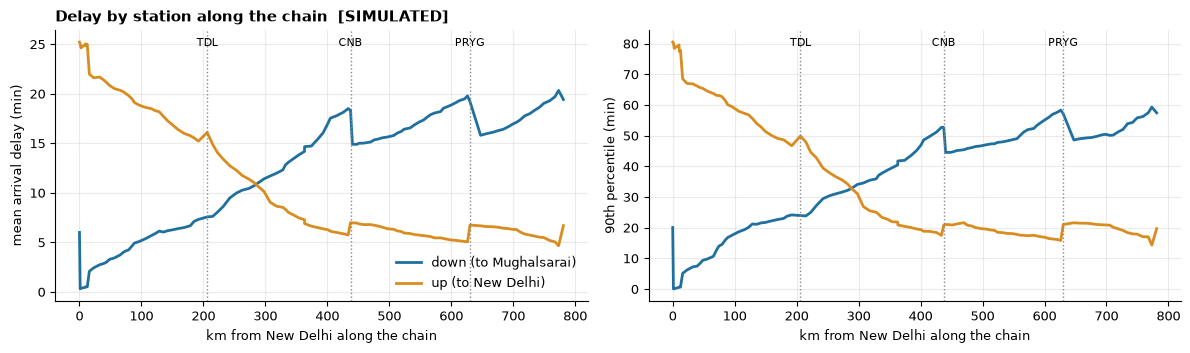

           min        max
direction                
-1         4.7  25.200001
 0         4.7   5.600000
 1         0.3  20.299999


In [3]:
g = a.groupby(["node", "direction"], observed=True).arrival_delay.agg(mean="mean", p90=lambda s: s.quantile(.9), n="size").reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharex=True)
for dr, c, lab in ((1, BLUE, "down (to Mughalsarai)"), (-1, ORANGE, "up (to New Delhi)")):
    s = g[g.direction == dr]
    axes[0].plot(km[s.node].values, s["mean"], color=c, lw=2, label=lab); axes[1].plot(km[s.node].values, s.p90, color=c, lw=2, label=lab)
for ax, yl in zip(axes, ["mean arrival delay (min)", "90th percentile (min)"]):
    ax.set_xlabel("km from New Delhi along the chain"); ax.set_ylabel(yl)
    for name in ["TDL", "CNB", "PRYG"]:
        x = km[int(nodes.set_index("node_name").node[name])]; ax.axvline(x, color=GREY, ls=":", lw=1); ax.text(x, ax.get_ylim()[1] * 0.97, name, ha="center", va="top", fontsize=8)
axes[0].legend(frameon=False); axes[0].set_title("Delay by station along the chain" + S, loc="left", fontweight="bold"); plt.tight_layout(); save(fig, "02_station_chain")
print(g.groupby("direction")["mean"].agg(["min", "max"]).round(1))

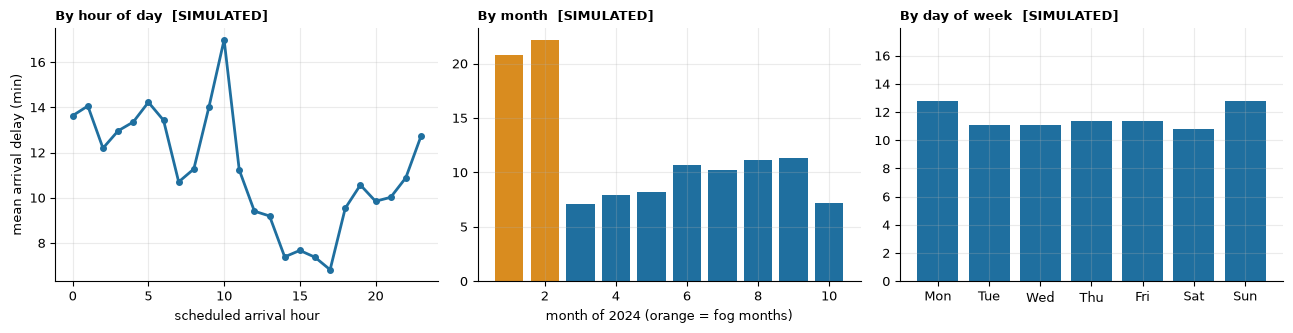

hour: lowest 6.8 at 17 h, highest 17.0 at 10 h
month means: {1: 20.799999237060547, 2: 22.100000381469727, 3: 7.099999904632568, 4: 8.0, 5: 8.199999809265137, 6: 10.699999809265137, 7: 10.199999809265137, 8: 11.199999809265137, 9: 11.300000190734863, 10: 7.199999809265137}
day-of-week means: {0: 12.779999732971191, 1: 11.109999656677246, 2: 11.069999694824219, 3: 11.380000114440918, 4: 11.359999656677246, 5: 10.800000190734863, 6: 12.819999694824219} | spread 2.02 min


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
h_ = a.groupby("sched_hour", observed=True).arrival_delay.agg(mean="mean", late=lambda s: (s > 10).mean())
axes[0].plot(h_.index, h_["mean"], color=BLUE, lw=2, marker="o", ms=4); axes[0].set_xlabel("scheduled arrival hour"); axes[0].set_ylabel("mean arrival delay (min)")
axes[0].set_title("By hour of day" + S, loc="left", fontweight="bold", fontsize=9)
m_ = a.groupby("month", observed=True).arrival_delay.agg(mean="mean", late=lambda s: (s > 10).mean())
axes[1].bar(m_.index, m_["mean"], color=[ORANGE if i in (1, 2) else BLUE for i in m_.index]); axes[1].set_xlabel("month of 2024 (orange = fog months)"); axes[1].set_title("By month" + S, loc="left", fontweight="bold", fontsize=9)
w_ = a.groupby("dow", observed=True).arrival_delay.mean()
axes[2].bar(range(7), w_.values, color=BLUE); axes[2].set_xticks(range(7)); axes[2].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[2].set_title("By day of week" + S, loc="left", fontweight="bold", fontsize=9); axes[2].set_ylim(0, w_.max() * 1.4)
plt.tight_layout(); save(fig, "03_hour_month_dow")
print("hour: lowest %.1f at %02d h, highest %.1f at %02d h" % (h_["mean"].min(), h_["mean"].idxmin(), h_["mean"].max(), h_["mean"].idxmax()))
print("month means:", m_["mean"].round(1).to_dict()); print("day-of-week means:", w_.round(2).to_dict(), "| spread %.2f min" % (w_.max() - w_.min()))

### By train type

Two cautions apply. **Exposure:** Passenger trains spend about 20 stops in the corridor and mostly start inside it; most Mail/Express trains enter mid-route with an unknown incoming delay; so raw mean delay mixes priority with route length and entry. The table therefore also shows rows per run, the share entering mid-route and the delay at the first row. **Shatabdi artifact:** the four Shatabdi trains are a known model artifact (two of them, 12003 and 12033, are delayed far more than their priority suggests), so per-train results for 12003 and 12033 are not interpreted and the Shatabdi row is shown with and without them.

               runs  rows_per_run  first_row_delay  gain_in_corridor  mean_delay  share_within_10  trains  share_mid_route_entry
type                                                                                                                            
Rajdhani       6100        107.16             2.25         19.059999    9.250000             0.77      20                   0.50
Duronto        2440        102.73             2.04         21.020000    9.010000             0.78       8                   0.38
Shatabdi       1220         60.25             1.47         28.760000   17.670000             0.65       4                   0.25
Superfast     32635         77.45             4.83         15.400000   12.160000             0.72     107                   0.68
Mail/Express  22875         45.38             7.12          9.230000   11.320000             0.73      75                   0.93
Passenger      2440         19.12             2.34          4.720000    7.620000             0.71

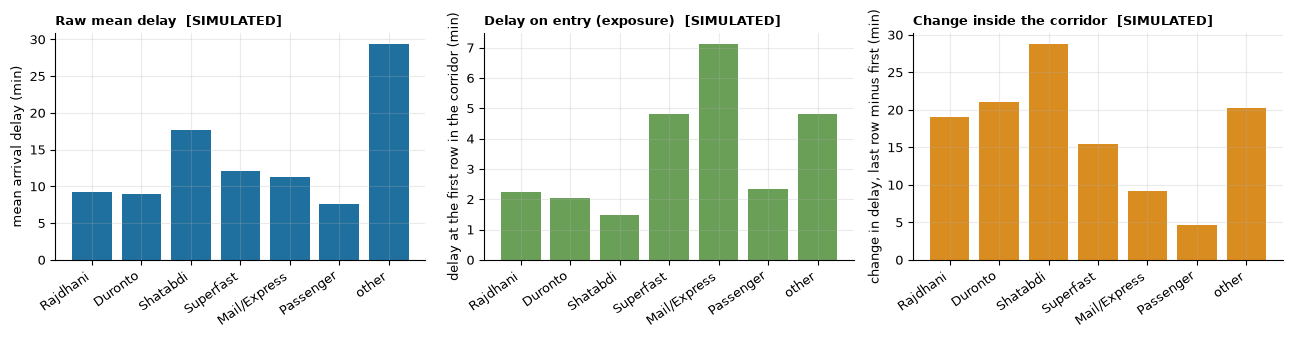

In [5]:
a_s = a.sort_values(["run_id", "abs_arr"])
runs = a_s.groupby("run_id", observed=True).agg(type=("type", "first"), train=("train", "first"), rows=("arrival_delay", "size"), first=("arrival_delay", "first"),
                                                last=("arrival_delay", "last"), mean=("arrival_delay", "mean"), total=("arrival_delay", lambda s: s.clip(lower=0).sum()))
runs["gain"] = runs["last"] - runs["first"]
tab = runs.groupby("type", observed=True).agg(runs=("rows", "size"), rows_per_run=("rows", "mean"), first_row_delay=("first", "mean"), gain_in_corridor=("gain", "mean"))
tab["mean_delay"] = a.groupby("type", observed=True).arrival_delay.mean()
tab["share_within_10"] = a.groupby("type", observed=True).arrival_delay.apply(lambda s: (s <= 10).mean())
tab["trains"] = pd.Series({t: sum(1 for s in tt.specs.values() if s.type == t) for t in tab.index})
tab["share_mid_route_entry"] = pd.Series({t: np.mean([s.entered_mid_route for s in tt.specs.values() if s.type == t]) for t in tab.index})
order = ["Rajdhani", "Duronto", "Shatabdi", "Superfast", "Mail/Express", "Passenger", "other"]
tab = tab.reindex(order)
sh = a[(a.type == "Shatabdi") & ~a.train.isin(eda.SHATABDI_ARTIFACT)]
print(tab.round(2).to_string())
print("\nShatabdi without 12003/12033 (the two trains with the artifact): mean delay %.1f, share within 10 min %.2f, rows %d" % (sh.arrival_delay.mean(), (sh.arrival_delay <= 10).mean(), len(sh)))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
x = np.arange(len(order))
axes[0].bar(x, tab.mean_delay, color=BLUE); axes[0].set_ylabel("mean arrival delay (min)"); axes[0].set_title("Raw mean delay" + S, loc="left", fontweight="bold", fontsize=9)
axes[1].bar(x, tab.first_row_delay, color=GREEN); axes[1].set_ylabel("delay at the first row in the corridor (min)"); axes[1].set_title("Delay on entry (exposure)" + S, loc="left", fontweight="bold", fontsize=9)
axes[2].bar(x, tab.gain_in_corridor, color=ORANGE); axes[2].set_ylabel("change in delay, last row minus first (min)"); axes[2].set_title("Change inside the corridor" + S, loc="left", fontweight="bold", fontsize=9)
for ax in axes: ax.set_xticks(x); ax.set_xticklabels(order, rotation=35, ha="right")
plt.tight_layout(); save(fig, "04_by_type")

            rows       mean        p90  share_within_10  days
weather                                                      
clear    3514966   8.700000  26.850000             0.78   231
fog       332372  37.209999  92.620003             0.33    22
rain      791727  13.800000  38.820000             0.66    52

fog days in the decision window by month: {1: 9, 2: 13}


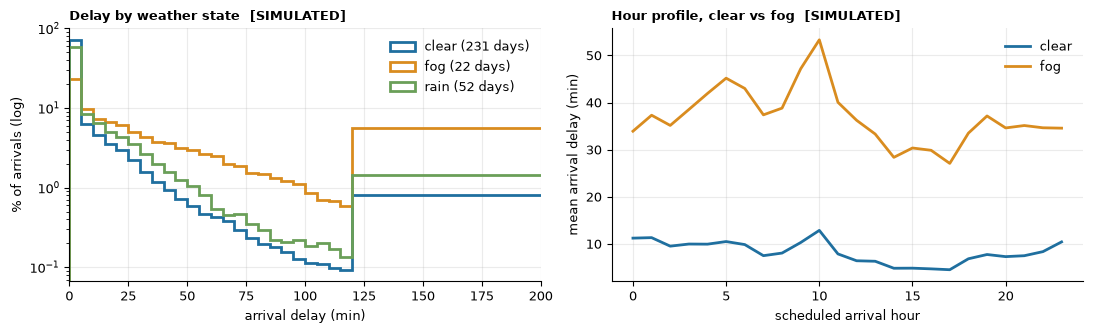

In [6]:
w = a.groupby("weather", observed=True).arrival_delay.agg(rows="size", mean="mean", p90=lambda s: s.quantile(.9), share_within_10=lambda s: (s <= 10).mean())
w["days"] = a.groupby("weather", observed=True).arr_date.nunique()
print(w.round(2).to_string())
print("\nfog days in the decision window by month:", a[a.weather == "fog"].groupby("month").arr_date.nunique().to_dict())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
cols = {"clear": BLUE, "fog": ORANGE, "rain": GREEN}
for k, c in cols.items():
    dd = a[a.weather == k].arrival_delay.clip(0, 600)
    axes[0].hist(dd, bins=np.r_[np.arange(0, 120, 5), 120, 600], weights=np.full(len(dd), 100 / len(dd)), histtype="step", lw=2, color=c, label=f"{k} ({a[a.weather == k].arr_date.nunique()} days)")
axes[0].set_yscale("log"); axes[0].set_xlim(0, 200); axes[0].set_xlabel("arrival delay (min)"); axes[0].set_ylabel("% of arrivals (log)"); axes[0].legend(frameon=False)
axes[0].set_title("Delay by weather state" + S, loc="left", fontweight="bold", fontsize=9)
clear_hour = a[a.weather == "clear"].groupby("sched_hour", observed=True).arrival_delay.mean(); fog_hour = a[a.weather == "fog"].groupby("sched_hour", observed=True).arrival_delay.mean()
axes[1].plot(clear_hour.index, clear_hour.values, color=BLUE, lw=2, label="clear"); axes[1].plot(fog_hour.index, fog_hour.values, color=ORANGE, lw=2, label="fog")
axes[1].set_xlabel("scheduled arrival hour"); axes[1].set_ylabel("mean arrival delay (min)"); axes[1].legend(frameon=False); axes[1].set_title("Hour profile, clear vs fog" + S, loc="left", fontweight="bold", fontsize=9)
plt.tight_layout(); save(fig, "05_weather")

### Descriptive only: monthly delay across the whole training window

**Not used for decisions.** Months after October 2024 (grey) are shown to see the pattern over time, including the Nov-Dec 2024 fog season that belongs to fold 1's validation range.

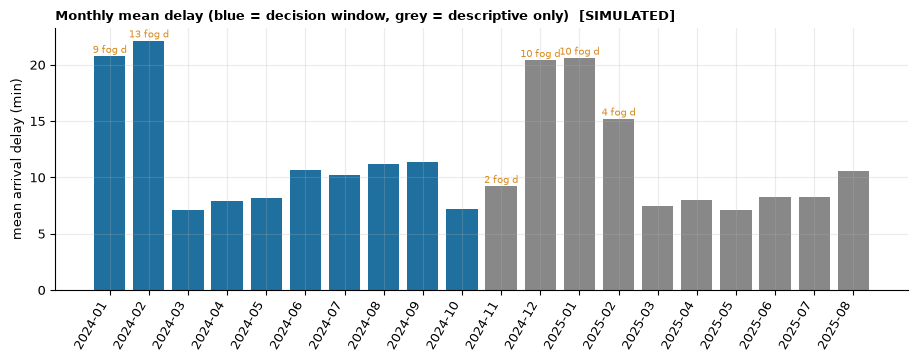

              mean      late fog_days used_for_decisions
2024-01  20.763006  0.410278        9               True
2024-02  22.133364  0.430963       13               True
2024-03    7.13579  0.187688        0               True
2024-04   7.954753  0.204409        0               True
2024-05   8.208939  0.211456        0               True
2024-06  10.689971  0.239807        0               True
2024-07  10.198617  0.283477        0               True
2024-08  11.181613  0.270275        0               True
2024-09  11.333388   0.28657        0               True
2024-10    7.16985  0.201707        0               True
2024-11   9.216974  0.241312        2              False
2024-12  20.396162  0.412757       10              False
2025-01  20.599836  0.415674       10              False
2025-02  15.196682  0.319172        4              False
2025-03   7.463294  0.195173        0              False
2025-04   8.039876  0.202636        0              False
2025-05   7.130245  0.191941   

In [7]:
mon = {}
for m_ in pd.period_range(DEC[0][:7], DESC[1][:7], freq="M"):
    s, e = m_.start_time.strftime("%Y-%m-%d"), m_.end_time.strftime("%Y-%m-%d")
    if e <= DEC[1]:
        a_m = a[(a.arr_date >= s) & (a.arr_date <= e)]
        used = True
    else:
        d_m, _, _, b_m = eda.load_window(s, e, tt=tt, nodes=nodes)
        a_m = eda.arrivals(d_m, b_m); used = False; del d_m
    mon[str(m_)] = dict(mean=a_m.arrival_delay.mean(), late=(a_m.arrival_delay > 10).mean(), fog_days=a_m[a_m.weather == "fog"].arr_date.nunique(), used_for_decisions=used)
mon = pd.DataFrame(mon).T
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(range(len(mon)), mon["mean"].astype(float), color=[BLUE if u else GREY for u in mon.used_for_decisions])
for i, f in enumerate(mon.fog_days):
    if f: ax.text(i, mon["mean"].astype(float).iloc[i] + 0.3, f"{int(f)} fog d", ha="center", fontsize=7, color=ORANGE)
ax.set_xticks(range(len(mon))); ax.set_xticklabels(mon.index, rotation=60, ha="right"); ax.set_ylabel("mean arrival delay (min)")
ax.set_title("Monthly mean delay (blue = decision window, grey = descriptive only)" + S, loc="left", fontweight="bold", fontsize=9); save(fig, "06_monthly_descriptive")
print(mon.round(2).to_string())

## 2. Delay along routes (decision window)

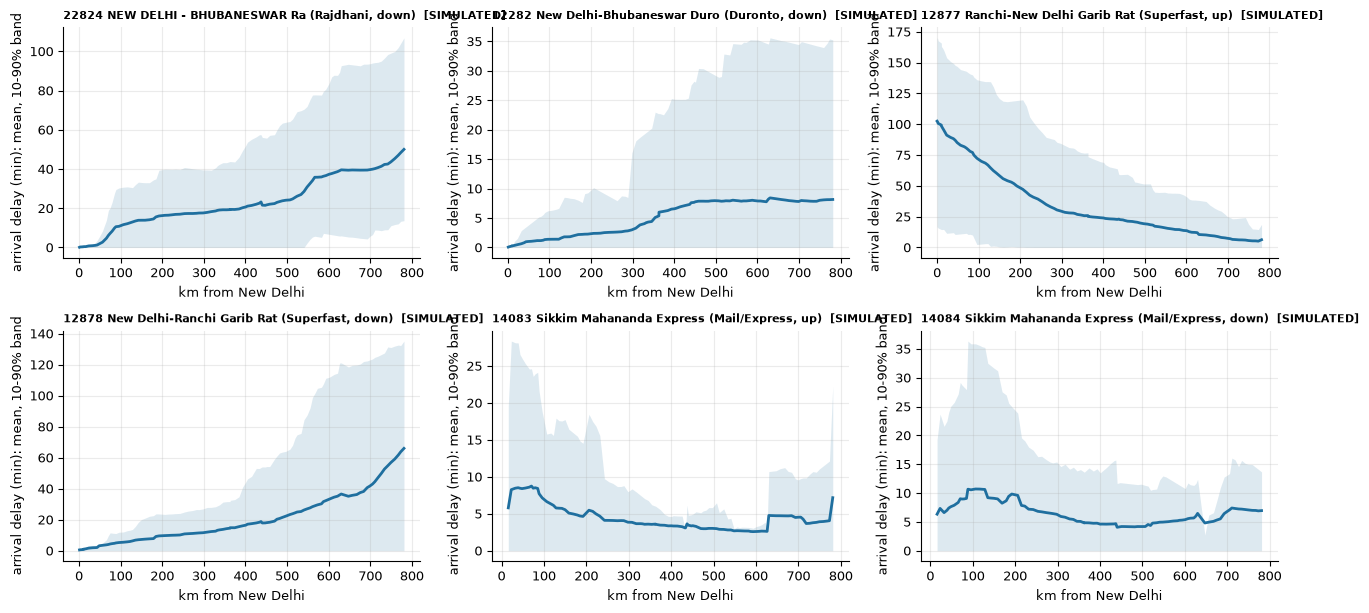

22824 NEW DELHI - BHUBANESWAR Rajdha rows/run   107 | mean delay first row   0.1 -> last row  50.0 (change +49.8)
12282 New Delhi-Bhubaneswar Duronto  rows/run   107 | mean delay first row   0.1 -> last row   8.2 (change +8.1)
12877 Ranchi-New Delhi Garib Rath    rows/run   108 | mean delay first row   6.3 -> last row 102.5 (change +96.2)
12878 New Delhi-Ranchi Garib Rath    rows/run   107 | mean delay first row   0.5 -> last row  65.8 (change +65.2)
14083 Sikkim Mahananda Express       rows/run   102 | mean delay first row   7.2 -> last row   5.8 (change -1.4)
14084 Sikkim Mahananda Express       rows/run   102 | mean delay first row   6.3 -> last row   7.0 (change +0.6)


In [8]:
by_type = {}
for tn, sp in tt.specs.items():
    if tn in eda.SHATABDI_ARTIFACT:
        continue
    by_type.setdefault(sp.type, []).append((len(sp.visits), tn))
pick = [sorted(by_type["Rajdhani"])[-1][1], sorted(by_type["Duronto"])[-1][1]] + [t for _, t in sorted(by_type["Superfast"])[-2:]] + [t for _, t in sorted(by_type["Mail/Express"])[-2:]]
names = tt.trains.set_index("number").name
fig, axes = plt.subplots(2, 3, figsize=(13, 6.2))
for ax, tn in zip(axes.ravel(), pick):
    dd = a[a.train == tn]
    g = dd.groupby("node", observed=True).arrival_delay.agg(mean="mean", p10=lambda s: s.quantile(.1), p90=lambda s: s.quantile(.9))
    xx = km[g.index].values
    ax.plot(xx, g["mean"], color=BLUE, lw=2); ax.fill_between(xx, g.p10, g.p90, color=BLUE, alpha=0.15, lw=0)
    sp = tt.specs[tn]
    ax.set_title(f"{tn} {names[tn][:26]} ({sp.type}, {'down' if dd.direction.iloc[0] > 0 else 'up'}){S}", fontsize=8, loc="left", fontweight="bold")
    ax.set_xlabel("km from New Delhi"); ax.set_ylabel("arrival delay (min): mean, 10-90% band")
plt.tight_layout(); save(fig, "07_routes")
for tn in pick:
    dd = a[a.train == tn].sort_values("abs_arr"); r = dd.groupby("run_id", observed=True).arrival_delay.agg(["first", "last", "size"])
    print(f"{tn} {names[tn][:30]:30s} rows/run {r['size'].mean():5.0f} | mean delay first row {r['first'].mean():5.1f} -> last row {r['last'].mean():5.1f} (change {(r['last'] - r['first']).mean():+.1f})")

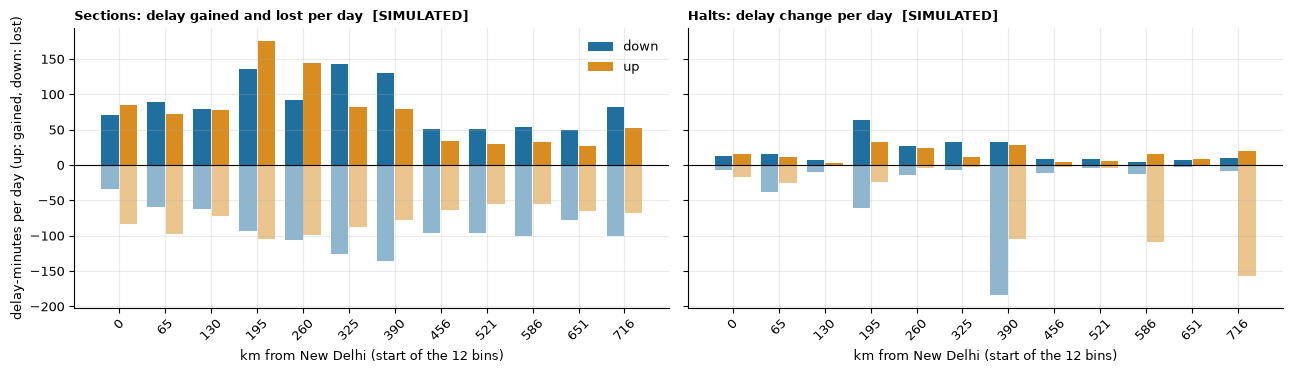

sections: total gained 1928 and lost -2017 delay-minutes per day (net -89)
halts: gained 410 and lost -851 delay-minutes per day (net -441); mean change -0.37 min per halt
section delta: mean -0.006 min, share of passages with delta > +1: 0.015, < -1: 0.005


largest mean gain per section type: first 10%% of the chain vs rest -> 0.023 -0.01


In [9]:
win = (df.abs_arr >= lo) & (df.abs_arr < hi)
sec = df[win & df.first_in_visit & df.arrival_delay.notna() & df.prev_node.notna() & df.prev_dep_delay.notna()]
sec = sec[(sec.node - sec.prev_node).abs() == 1]
sec = sec.assign(delta=sec.arrival_delay.astype("float64") - sec.prev_dep_delay.astype("float64"), pos=sec.prev_node.map(km).astype(float))
dwell = (df.scheduled_departure.astype("float64") - df.scheduled_arrival.astype("float64"))
hal = df[win & (dwell > 0.01) & df.arrival_delay.notna() & df.departure_delay.notna()]
hal = hal.assign(delta=hal.departure_delay.astype("float64") - hal.arrival_delay.astype("float64"), pos=hal.node.map(km).astype(float))
bins = np.linspace(0, float(km.max()) + 1, 13); days = (pd.Timestamp(DEC[1]) - pd.Timestamp(DEC[0])).days + 1
def gl(t):
    b = pd.cut(t.pos, bins, labels=False).rename("bin")
    dr = t.direction.astype(int).rename("direction")
    return t.groupby([b, dr], observed=True).delta.agg(gain=lambda s: s.clip(lower=0).sum(), loss=lambda s: s.clip(upper=0).sum(), n="size").reset_index()
gs, gh = gl(sec), gl(hal)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, tb, ttl in ((axes[0], gs, "Sections: delay gained and lost per day"), (axes[1], gh, "Halts: delay change per day")):
    for dr, c, off in ((1, BLUE, -0.2), (-1, ORANGE, 0.2)):
        s = tb[tb.direction == dr]
        ax.bar(s.bin + off, s.gain / days, 0.38, color=c, label="down" if dr == 1 else "up"); ax.bar(s.bin + off, s.loss / days, 0.38, color=c, alpha=0.5)
    ax.axhline(0, color="black", lw=0.8); ax.set_xticks(range(12)); ax.set_xticklabels([f"{int(bins[i])}" for i in range(12)], rotation=45); ax.set_xlabel("km from New Delhi (start of the 12 bins)")
    ax.set_title(ttl + S, loc="left", fontweight="bold", fontsize=9)
axes[0].set_ylabel("delay-minutes per day (up: gained, down: lost)"); axes[0].legend(frameon=False); plt.tight_layout(); save(fig, "08_gain_loss")
print("sections: total gained %.0f and lost %.0f delay-minutes per day (net %+.0f)" % (sec.delta.clip(lower=0).sum() / days, sec.delta.clip(upper=0).sum() / days, sec.delta.sum() / days))
print("halts: gained %.0f and lost %.0f delay-minutes per day (net %+.0f); mean change %.2f min per halt" % (hal.delta.clip(lower=0).sum() / days, hal.delta.clip(upper=0).sum() / days, hal.delta.sum() / days, hal.delta.mean()))
print("section delta: mean %+.3f min, share of passages with delta > +1: %.3f, < -1: %.3f" % (sec.delta.mean(), (sec.delta > 1).mean(), (sec.delta < -1).mean()))
print("largest mean gain per section type: first 10%% of the chain vs rest ->", round(sec[sec.pos < km.max() * .1].delta.mean(), 3), round(sec[sec.pos >= km.max() * .1].delta.mean(), 3))

## 3. Dependence between neighbouring stations, trains and hours (decision window)

correlation of arrival delay at stop i and stop i+k (same train, consecutive node visits): {1: 0.996, 2: 0.99, 3: 0.984, 5: 0.971, 10: 0.932, 20: 0.846, 40: 0.676}
regression of delay at the next stop on delay now: slope 1.008, intercept 0.11 min


correlation of the change (next minus now) with delay now: 0.087 (negative = recovery of large delays)


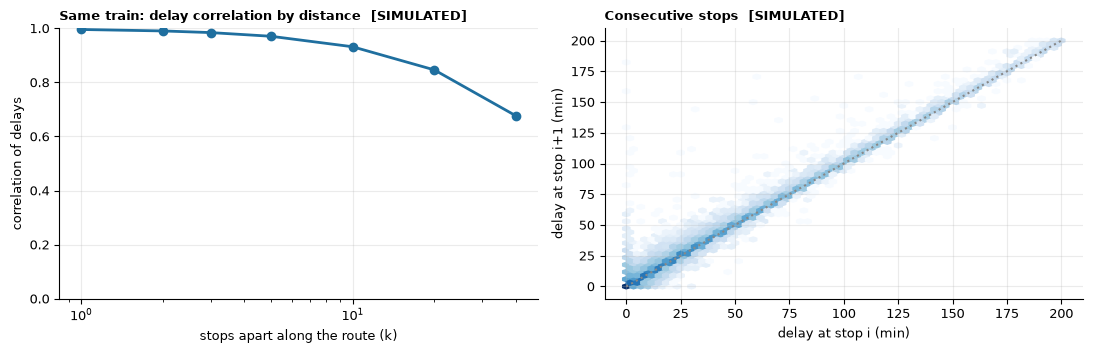

In [10]:
a_s = a.sort_values(["run_id", "abs_arr"])
gdel = a_s.groupby("run_id", observed=True).arrival_delay
lag = {k: float(a_s.arrival_delay.corr(gdel.shift(k))) for k in (1, 2, 3, 5, 10, 20, 40)}
nxt = gdel.shift(-1)
ok = nxt.notna()
slope, icpt = np.polyfit(a_s.arrival_delay[ok].astype(float), nxt[ok].astype(float), 1)
inc = (nxt - a_s.arrival_delay)[ok]
print("correlation of arrival delay at stop i and stop i+k (same train, consecutive node visits):", {k: round(v, 3) for k, v in lag.items()})
print("regression of delay at the next stop on delay now: slope %.3f, intercept %.2f min" % (slope, icpt))
print("correlation of the change (next minus now) with delay now: %.3f (negative = recovery of large delays)" % inc.corr(a_s.arrival_delay[ok]))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(list(lag), list(lag.values()), marker="o", color=BLUE, lw=2); axes[0].set_xscale("log"); axes[0].set_xlabel("stops apart along the route (k)"); axes[0].set_ylabel("correlation of delays"); axes[0].set_ylim(0, 1)
axes[0].set_title("Same train: delay correlation by distance" + S, loc="left", fontweight="bold", fontsize=9)
samp = np.random.default_rng(0).choice(np.nonzero(ok.values)[0], 150000, replace=False)
x_, y_ = a_s.arrival_delay.to_numpy()[samp].astype(float), nxt.to_numpy()[samp].astype(float)
axes[1].hexbin(x_, y_, gridsize=60, bins="log", cmap="Blues", extent=(0, 200, 0, 200)); axes[1].plot([0, 200], [0, 200], color=GREY, ls=":")
axes[1].set_xlabel("delay at stop i (min)"); axes[1].set_ylabel("delay at stop i+1 (min)"); axes[1].set_title("Consecutive stops" + S, loc="left", fontweight="bold", fontsize=9)
plt.tight_layout(); save(fig, "09_same_train_dependence")

       gap   pairs  corr_raw  corr_residual
    [0, 2) 1053601     0.800          0.754
    [2, 5)  662604     0.573          0.495
   [5, 10)  625501     0.522          0.437
  [10, 20)  912558     0.476          0.400
  [20, 30)  502423     0.450          0.356
  [30, 60)  571676     0.387          0.276
 [60, 120)  192382     0.345          0.239
[120, 360)  114433     0.137          0.086
share of consecutive different-train arrivals at a node within 10 min: 0.505


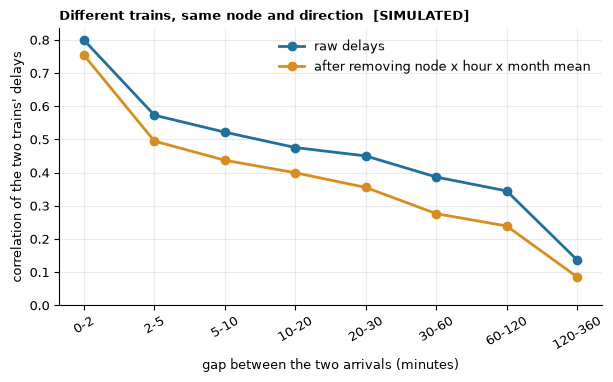

In [11]:
resid = eda.residualise(a)
pr = eda.same_node_pairs(a, resid)
pr = pr[~pr.same_train]
edges_ = [0, 2, 5, 10, 20, 30, 60, 120, 360]
pr["bin"] = pd.cut(pr.gap, edges_, right=False)
rows = []
for b, g in pr.groupby("bin", observed=True):
    rows.append(dict(gap=str(b), pairs=len(g), corr_raw=g.delay.corr(g.prev_delay), corr_residual=g.resid.corr(g.prev_resid)))
cb = pd.DataFrame(rows)
print(cb.round(3).to_string(index=False))
print("share of consecutive different-train arrivals at a node within 10 min: %.3f" % (pr.gap < 10).mean())
fig, ax = plt.subplots(figsize=(7, 3.6))
xs = np.arange(len(cb))
ax.plot(xs, cb.corr_raw, marker="o", color=BLUE, lw=2, label="raw delays"); ax.plot(xs, cb.corr_residual, marker="o", color=ORANGE, lw=2, label="after removing node x hour x month mean")
ax.set_xticks(xs); ax.set_xticklabels([g.replace("[", "").replace(")", "").replace(", ", "-") for g in cb.gap], rotation=30); ax.set_xlabel("gap between the two arrivals (minutes)")
ax.set_ylabel("correlation of the two trains' delays"); ax.legend(frameon=False); ax.set_ylim(0, None); ax.set_title("Different trains, same node and direction" + S, loc="left", fontweight="bold", fontsize=9)
save(fig, "10_different_trains")

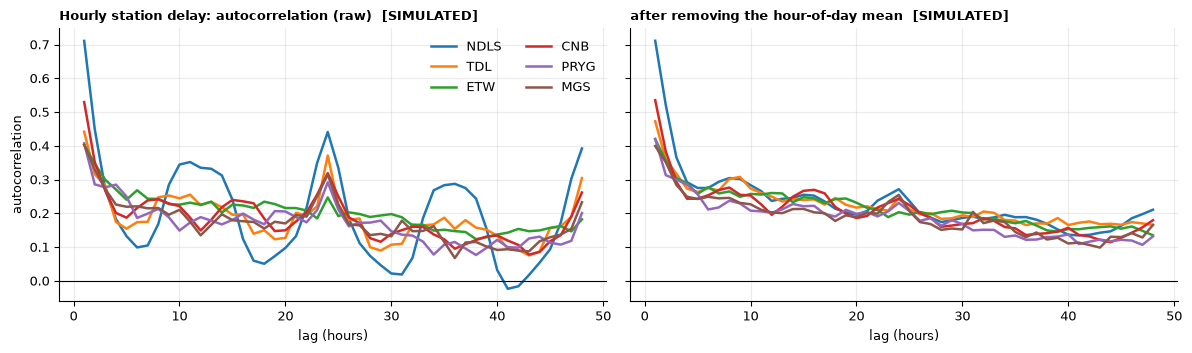

                  NDLS   TDL   ETW   CNB  PRYG   MGS
lag 1h raw        0.71  0.44  0.40  0.53  0.41  0.40
lag 2h raw        0.45  0.32  0.35  0.35  0.29  0.33
lag 3h raw        0.27  0.28  0.30  0.27  0.28  0.27
lag 6h raw        0.10  0.17  0.27  0.22  0.19  0.22
lag 12h raw       0.33  0.22  0.23  0.15  0.19  0.13
lag 24h raw       0.44  0.37  0.25  0.32  0.29  0.31
lag 1h deseason   0.71  0.47  0.42  0.54  0.42  0.40
lag 3h deseason   0.37  0.32  0.30  0.29  0.30  0.28
lag 6h deseason   0.27  0.27  0.28  0.25  0.21  0.25
lag 12h deseason  0.24  0.25  0.26  0.20  0.20  0.20
lag 24h deseason  0.27  0.25  0.20  0.24  0.23  0.25


In [12]:
mean, cnt = eda.node_hour_arrays(a, n_nodes, n_hours)
num = np.where(cnt > 0, mean * cnt, 0).sum(axis=1); den = cnt.sum(axis=1)
pooled = np.where(den > 0, num / np.maximum(den, 1), np.nan)
hod = np.arange(n_hours) % 24
sel = ["NDLS", "TDL", "ETW", "CNB", "PRYG", "MGS"]
nm = nodes.set_index("node_name").node
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
res = {}
for name in sel:
    s = pd.Series(pooled[int(nm[name])]).interpolate(limit=3, limit_area="inside")
    r_ = s - s.groupby(hod).transform("mean")
    res[name] = (eda.acf(s, 48), eda.acf(r_, 48))
    axes[0].plot(range(1, 49), res[name][0], label=name, lw=1.8); axes[1].plot(range(1, 49), res[name][1], label=name, lw=1.8)
axes[0].set_title("Hourly station delay: autocorrelation (raw)" + S, loc="left", fontweight="bold", fontsize=9); axes[1].set_title("after removing the hour-of-day mean" + S, loc="left", fontweight="bold", fontsize=9)
for ax in axes: ax.set_xlabel("lag (hours)"); ax.axhline(0, color="black", lw=0.8)
axes[0].set_ylabel("autocorrelation"); axes[0].legend(frameon=False, ncol=2); plt.tight_layout(); save(fig, "11_station_acf")
print(pd.DataFrame({n: {f"lag {k}h raw": res[n][0][k - 1] for k in (1, 2, 3, 6, 12, 24)} | {f"lag {k}h deseason": res[n][1][k - 1] for k in (1, 3, 6, 12, 24)} for n in sel}).round(2).to_string())

## 4. Persistence: how long does a station stay disturbed?

A node and direction is **disturbed** from the first hour its mean arrival delay reaches **30 minutes** until the first hour it falls below **15 minutes** (both thresholds fixed in advance; hours with no arrivals are filled over gaps of up to 3 hours). Episodes still open at the end of the window are censored. The curve is a Kaplan-Meier "still disturbed" survival curve by the season of the onset.

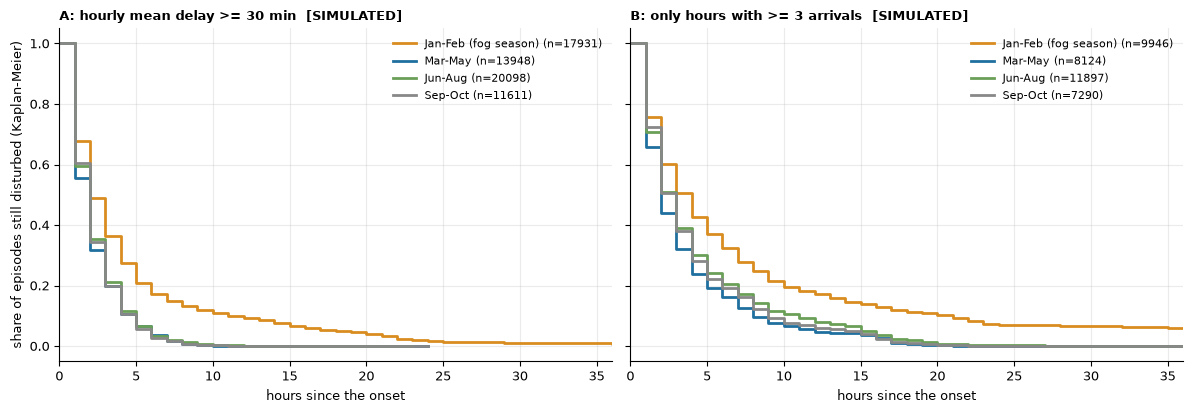

                                      definition               season  episodes  censored  median_hours  still_disturbed_after_3h  after_6h  after_12h
A: hourly mean >= 30 min (gaps up to 3 h filled) Jan-Feb (fog season)     17931       0.0             2                      0.36      0.17       0.09
A: hourly mean >= 30 min (gaps up to 3 h filled)              Mar-May     13948       0.0             2                      0.20      0.04       0.00
A: hourly mean >= 30 min (gaps up to 3 h filled)              Jun-Aug     20098       0.0             2                      0.21      0.03       0.00
A: hourly mean >= 30 min (gaps up to 3 h filled)              Sep-Oct     11611       0.0             2                      0.20      0.03       0.00
          B: same, only hours with >= 3 arrivals Jan-Feb (fog season)      9946       0.0             4                      0.51      0.32       0.17
          B: same, only hours with >= 3 arrivals              Mar-May      8124       0.0     

In [13]:
yi = eda.interpolate_gaps(mean, 3)
yi_strict = np.where(cnt >= 3, mean, np.nan)           # definition B: only hours with at least 3 arrivals count
def persistence(series_arr, label):
    ep = []
    for n in range(n_nodes):
        for di in range(2):
            for onset, dur, rec in eda.disturbance_episodes(series_arr[n, di], 30, 15):
                ep.append((n, di, onset, dur, rec))
    ep = pd.DataFrame(ep, columns=["node", "dir", "onset", "dur", "recovered"])
    ep["month"] = (pd.Timestamp(DEC[0]) + pd.to_timedelta(ep.onset, unit="h")).dt.month
    ep["season"] = eda.season_of(ep.month.to_numpy())
    curves, rows = {}, []
    for sname in eda.SEASONS[:4]:
        e_ = ep[ep.season == sname]
        if len(e_) < 20: continue
        k = eda.kaplan_meier(e_.dur.to_numpy(), e_.recovered.to_numpy()); curves[sname] = (k, len(e_))
        med = k.time[k.survival <= 0.5].min() if (k.survival <= 0.5).any() else np.nan
        s3, s6, s12 = [float(k.survival[k.time <= t_].iloc[-1]) for t_ in (3, 6, 12)]
        rows.append(dict(definition=label, season=sname, episodes=len(e_), censored=float(1 - e_.recovered.mean()), median_hours=med, still_disturbed_after_3h=s3, after_6h=s6, after_12h=s12))
    return ep, curves, pd.DataFrame(rows)
epA, cA, tA = persistence(yi, "A: hourly mean >= 30 min (gaps up to 3 h filled)")
epB, cB, tB = persistence(yi_strict, "B: same, only hours with >= 3 arrivals")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, curves, ttl in ((axes[0], cA, "A: hourly mean delay >= 30 min"), (axes[1], cB, "B: only hours with >= 3 arrivals")):
    for (sname, (k, n_)), c in zip(curves.items(), (ORANGE, BLUE, GREEN, GREY)):
        ax.step(k.time, k.survival, where="post", color=c, lw=2, label=f"{sname} (n={n_})")
    ax.set_xlim(0, 36); ax.set_xlabel("hours since the onset"); ax.legend(frameon=False, fontsize=8); ax.set_title(ttl + S, loc="left", fontweight="bold", fontsize=9)
axes[0].set_ylabel("share of episodes still disturbed (Kaplan-Meier)")
plt.tight_layout(); save(fig, "12_persistence")
print(pd.concat([tA, tB]).round(2).to_string(index=False))
print("\nNote: with ~3-4 arrivals per node, direction and hour, one late train can start an episode; definition B needs several trains.")

## 5. Heavy tails

68,625 runs. Worst 1% of runs account for 15.4% of all delay-minutes, worst 5% for 42.4%, worst 10% for 60.4%, worst 20% for 80.1%.
By arrival rows: the worst 1% of arrivals carry 15.4% and the worst 5% carry 44.2%.
By day: the worst 5% of days carry 17.3% and the worst 10% carry 29.1% of delay-minutes (305 days).


worst 5% of runs, share of delay-minutes by season: {'Jan-Feb (fog season)': 0.332, 'Jun-Aug': 0.419, 'Mar-May': 0.465, 'Sep-Oct': 0.415}


share of runs with at least one arrival over 60 min: 0.109; over 120 min: 0.031


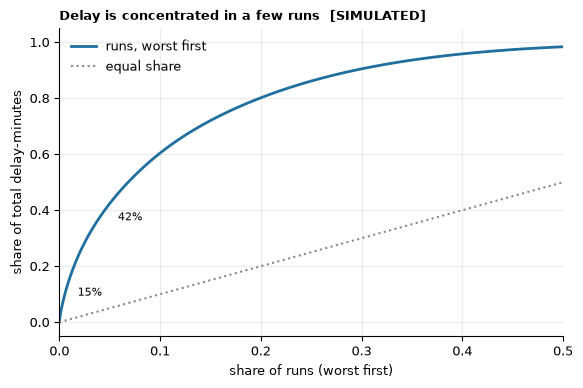

In [14]:
tot = runs["total"].sort_values(ascending=False)
n_runs = len(tot); csum = tot.cumsum() / tot.sum()
share = {p: float(csum.iloc[int(n_runs * p) - 1]) for p in (0.01, 0.05, 0.10, 0.20)}
rows_sorted = a.arrival_delay.clip(lower=0).sort_values(ascending=False).to_numpy()
rs = {p: float(rows_sorted[: int(len(rows_sorted) * p)].sum() / rows_sorted.sum()) for p in (0.01, 0.05)}
day_tot = a.groupby("arr_date", observed=True).arrival_delay.apply(lambda s: s.clip(lower=0).sum()).sort_values(ascending=False)
ds = {p: float(day_tot.iloc[: max(int(len(day_tot) * p), 1)].sum() / day_tot.sum()) for p in (0.05, 0.10)}
print(f"{n_runs:,} runs. Worst 1% of runs account for {share[0.01]:.1%} of all delay-minutes, worst 5% for {share[0.05]:.1%}, worst 10% for {share[0.10]:.1%}, worst 20% for {share[0.20]:.1%}.")
print(f"By arrival rows: the worst 1% of arrivals carry {rs[0.01]:.1%} and the worst 5% carry {rs[0.05]:.1%}.")
print(f"By day: the worst 5% of days carry {ds[0.05]:.1%} and the worst 10% carry {ds[0.10]:.1%} of delay-minutes ({len(day_tot)} days).")
runs["season"] = eda.season_of(a_s.groupby("run_id", observed=True).month.first().reindex(runs.index).to_numpy())
bys = {s: float(g.total.sort_values(ascending=False).iloc[: max(int(len(g) * 0.05), 1)].sum() / g.total.sum()) for s, g in runs.groupby("season")}
print("worst 5% of runs, share of delay-minutes by season:", {k: round(v, 3) for k, v in bys.items()})
print("share of runs with at least one arrival over 60 min: %.3f; over 120 min: %.3f" % ((a.groupby("run_id", observed=True).arrival_delay.max() > 60).mean(), (a.groupby("run_id", observed=True).arrival_delay.max() > 120).mean()))
fig, ax = plt.subplots(figsize=(6.5, 4))
xs = np.arange(1, n_runs + 1) / n_runs
ax.plot(xs, csum.values, color=BLUE, lw=2, label="runs, worst first"); ax.plot([0, 1], [0, 1], color=GREY, ls=":", label="equal share")
ax.set_xlim(0, 0.5); ax.set_xlabel("share of runs (worst first)"); ax.set_ylabel("share of total delay-minutes"); ax.legend(frameon=False)
for p in (0.01, 0.05): ax.annotate(f"{share[p]:.0%}", (p, share[p]), textcoords="offset points", xytext=(6, -12), fontsize=8)
ax.set_title("Delay is concentrated in a few runs" + S, loc="left", fontweight="bold", fontsize=9); save(fig, "13_heavy_tails")

## 6. Which predictors look informative for 1-6 hour forecasts?

This is **evidence for choosing candidate features later**; no prediction table is built or saved. The analysis frame is hourly delay per node and direction (mean arrival delay of the trains that arrived in that hour). The target is the same node and direction `h` hours later. Spearman correlations use the whole decision window; the linear R-squared gains fit on Jan-Jul 2024 and score on Aug-Oct 2024 (time-ordered). **Weather** is used as if a forecast were available (state of the target day); the current state is also tried. Scheduled congestion is the timetable's trains per hour on the section into the node.

In [15]:
from sklearn.linear_model import LinearRegression
Hs = n_hours
y = mean; yi = eda.interpolate_gaps(mean, 3)
split_H = int((pd.Timestamp("2024-08-01") - pd.Timestamp(DEC[0])).days * 24)
fit_vals = np.where(np.arange(Hs) < split_H, y, np.nan)
hist = np.stack([np.nanmean(fit_vals[:, :, hod == h], axis=2) for h in range(24)], axis=2)
dates = pd.Timestamp(DEC[0]) + pd.to_timedelta(np.arange(Hs) // 24, unit="D")
wd = a.groupby("arr_date", observed=True).weather.agg(lambda s: s.value_counts().index[0])
wstate = pd.Series(dates).map(wd.to_dict()).fillna("clear").to_numpy()
fog_h, rain_h = (wstate == "fog").astype(float), (wstate == "rain").astype(float)
cong = np.zeros((n_nodes, 2, 24))
for r in edges.itertuples():
    di = 0 if r.direction == 1 else 1
    cong[r.to_node, di, :] = [getattr(r, f"trains_hour_{h:02d}") for h in range(24)]
def upstream(arr, k):
    out = np.full_like(arr, np.nan); out[k:, 0, :] = arr[:-k, 0, :]; out[:-k, 1, :] = arr[k:, 1, :]; return out
up1, up3 = upstream(yi, 1), upstream(yi, 3)
opp = yi[:, ::-1, :]
def frame(h):
    Hr = np.arange(1, Hs - h)
    t = y[:, :, Hr + h]
    f = {"own current delay": yi[:, :, Hr], "own trend (now - 1h ago)": yi[:, :, Hr] - yi[:, :, Hr - 1], "arrivals this hour": cnt[:, :, Hr].astype(float),
         "upstream node (1 step) delay": up1[:, :, Hr], "upstream node (3 steps) delay": up3[:, :, Hr], "opposite direction, same node": opp[:, :, Hr],
         "hour-of-day mean (history)": hist[:, :, hod[Hr + h]], "fog now": np.broadcast_to(fog_h[Hr], t.shape), "rain now": np.broadcast_to(rain_h[Hr], t.shape),
         "fog at target hour (forecast)": np.broadcast_to(fog_h[Hr + h], t.shape), "rain at target hour (forecast)": np.broadcast_to(rain_h[Hr + h], t.shape),
         "scheduled trains/hour (timetable)": cong[:, :, hod[Hr + h]]}
    return Hr, t, f
rows = []
for h in (1, 3, 6):
    Hr, t, f = frame(h)
    rng = np.random.default_rng(h)
    for name, arr in f.items():
        ok = np.isfinite(arr) & np.isfinite(t)
        idx = np.flatnonzero(ok.ravel()); idx = rng.choice(idx, min(len(idx), 200000), replace=False)
        v = arr.ravel()[idx]
        rows.append((h, name, float(pd.Series(v).corr(pd.Series(t.ravel()[idx]), method="spearman")) if np.std(v) > 0 else np.nan))
ev = pd.DataFrame(rows, columns=["h", "feature", "spearman"]).pivot(index="feature", columns="h", values="spearman").round(3)
print(ev.sort_values(1, ascending=False).to_string())

h                                      1      3      6
feature                                               
upstream node (3 steps) delay      0.545  0.253  0.155
hour-of-day mean (history)         0.478  0.477  0.480
upstream node (1 step) delay       0.440  0.243  0.164
own current delay                  0.386  0.237  0.165
fog now                            0.299  0.301  0.295
fog at target hour (forecast)      0.298  0.296  0.296
rain at target hour (forecast)     0.170  0.171  0.167
rain now                           0.167  0.167  0.163
own trend (now - 1h ago)           0.144  0.074 -0.009
arrivals this hour                 0.119  0.117  0.017
opposite direction, same node      0.113  0.099  0.092
scheduled trains/hour (timetable)  0.029  0.028  0.026


h                               1      2      3      4      5      6
feature set                                                         
current delay               0.251  0.083  0.023 -0.002 -0.017 -0.029
+ trend, arrivals           0.254  0.085  0.025 -0.004 -0.020 -0.034
+ upstream, opposite        0.452  0.134  0.044  0.003 -0.015 -0.033
+ hour-of-day history       0.570  0.422  0.385  0.369  0.361  0.350
+ weather (forecast + now)  0.581  0.447  0.415  0.404  0.399  0.392
+ scheduled congestion      0.581  0.447  0.414  0.404  0.399  0.392

MAE (min):
h                              1      2      3      4      5      6
feature set                                                        
current delay               9.56  10.83  11.19  11.41  11.41  11.35
+ trend, arrivals           9.55  10.77  11.14  11.35  11.34  11.30
+ upstream, opposite        7.67  10.45  10.98  11.26  11.30  11.27
+ hour-of-day history       6.77   8.19   8.31   8.30   8.25   8.25
+ weather (forecast + now)  

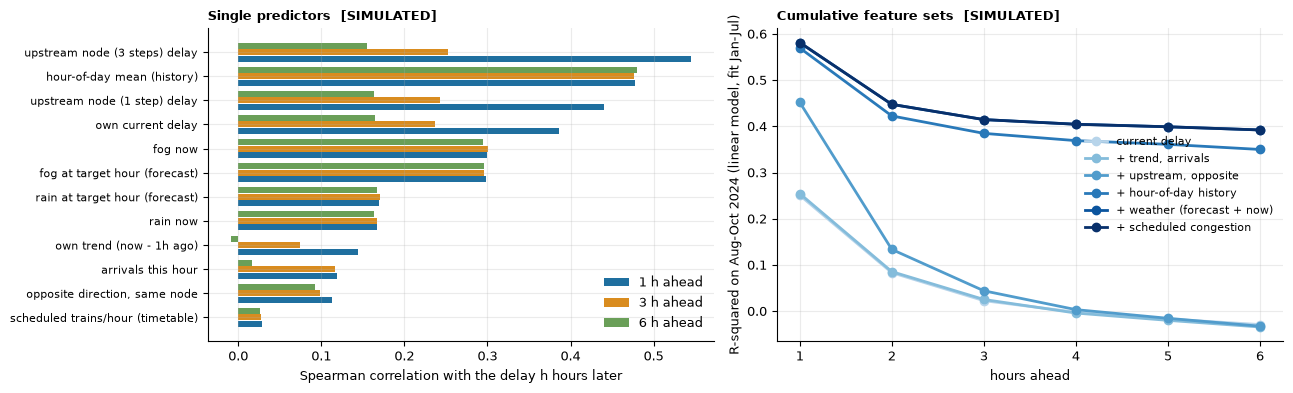

In [16]:
sets = [("current delay", ["own current delay"]),
        ("+ trend, arrivals", ["own trend (now - 1h ago)", "arrivals this hour"]),
        ("+ upstream, opposite", ["upstream node (1 step) delay", "upstream node (3 steps) delay", "opposite direction, same node"]),
        ("+ hour-of-day history", ["hour-of-day mean (history)"]),
        ("+ weather (forecast + now)", ["fog now", "rain now", "fog at target hour (forecast)", "rain at target hour (forecast)"]),
        ("+ scheduled congestion", ["scheduled trains/hour (timetable)"])]
allnames = [n for _, g in sets for n in g]
rr = []
for h in (1, 2, 3, 4, 5, 6):
    Hr, t, f = frame(h)
    ok = np.isfinite(t)
    for n in allnames: ok &= np.isfinite(f[n])
    Hmat = np.broadcast_to(Hr, t.shape)
    fit_m, ev_m = ok & (Hmat + h < split_H), ok & (Hmat >= split_H)
    cols, used = [], []
    for sname, names_ in sets:
        used += names_
        X = np.stack([f[n][fit_m] for n in used], axis=1); Xe = np.stack([f[n][ev_m] for n in used], axis=1)
        mdl = LinearRegression().fit(X, t[fit_m]); p = mdl.predict(Xe)
        sc = eda.scores(t[ev_m], p); rr.append((h, sname, sc["R2"], sc["MAE"], sc["n"]))
r2 = pd.DataFrame(rr, columns=["h", "feature set", "R2", "MAE", "n"])
print(r2.pivot(index="feature set", columns="h", values="R2").reindex([s for s, _ in sets]).round(3).to_string())
print("\nMAE (min):"); print(r2.pivot(index="feature set", columns="h", values="MAE").reindex([s for s, _ in sets]).round(2).to_string())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
evs = ev.sort_values(1)
yy = np.arange(len(evs))
for k, (h, c) in enumerate(((1, BLUE), (3, ORANGE), (6, GREEN))):
    axes[0].barh(yy + (k - 1) * 0.27, evs[h].fillna(0), 0.25, color=c, label=f"{h} h ahead")
axes[0].set_yticks(yy); axes[0].set_yticklabels(evs.index, fontsize=8); axes[0].set_xlabel("Spearman correlation with the delay h hours later"); axes[0].legend(frameon=False)
axes[0].set_title("Single predictors" + S, loc="left", fontweight="bold", fontsize=9)
for (sname, _), c in zip(sets, plt.cm.Blues(np.linspace(0.3, 1, len(sets)))):
    s = r2[r2["feature set"] == sname]; axes[1].plot(s.h, s.R2, marker="o", color=c, lw=2, label=sname)
axes[1].set_xlabel("hours ahead"); axes[1].set_ylabel("R-squared on Aug-Oct 2024 (linear model, fit Jan-Jul)"); axes[1].legend(frameon=False, fontsize=8)
axes[1].set_title("Cumulative feature sets" + S, loc="left", fontweight="bold", fontsize=9); plt.tight_layout(); save(fig, "14_feature_evidence")

## 7. Baseline preview: what the models must beat

Time-ordered split **inside the decision window**: history (and any fitted constants) from **2024-01-01 .. 2024-07-31**, scored on **2024-08-01 .. 2024-10-31**. Two views of "delay h hours later": (A) the hourly mean delay of a node and direction, and (B) the delay of a specific train at its own later stop. Baselines: **persistence** (delay stays the same), **node x hour history** (mean delay at that node and scheduled hour), **train x node history**, and **linear on current delay** (a constant and one slope fitted on the history period). Results for the fog season of Nov-Dec 2024 are shown separately and are **descriptive only**.

In [17]:
split_abs = lo + split_H * 60
rowsA = []
for h in range(1, 7):
    Hr = np.arange(1, Hs - h)
    tgt = y[:, :, Hr + h]; now = yi[:, :, Hr]; hp = hist[:, :, hod[Hr + h]]
    ok = np.isfinite(tgt) & np.isfinite(now) & np.isfinite(hp) & (np.broadcast_to(Hr, tgt.shape) >= split_H)
    for name, pred in (("persistence", now), ("node x hour history", hp)):
        sc = eda.scores(tgt[ok], pred[ok]); rowsA.append(dict(view="A hourly node mean", h=h, method=name, **sc))
fit_a = a[a.abs_arr < split_abs]
H_nh = fit_a.groupby(["node", "sched_hour"], observed=True).arrival_delay.mean().unstack().reindex(index=range(n_nodes), columns=range(24)).to_numpy()
g_mean = float(fit_a.arrival_delay.mean())
H_tn = fit_a.groupby(["train", "node"], observed=True).arrival_delay.mean()
H_tn.index = pd.MultiIndex.from_arrays([H_tn.index.get_level_values(0).astype(str), H_tn.index.get_level_values(1)])
def eval_B(a_all, H_nh, H_tn, g_mean, t_eval_lo, t_fit_hi, tag, lin=None):
    out, lins = [], {}
    for h in range(1, 7):
        P = eda.horizon_pairs(a_all, h)
        if lin is None:
            fitp = P[P.t_tgt < t_fit_hi]
            lins[h] = np.polyfit(fitp.delay_now.astype(float), fitp.delay_tgt.astype(float), 1)
        else:
            lins[h] = lin[h]
        b1, b0 = lins[h]
        evp = P[P.t_now >= t_eval_lo]
        pn = H_nh[evp.node_tgt.to_numpy(), evp.sched_hour_tgt.to_numpy()]; pn = np.where(np.isfinite(pn), pn, g_mean)
        ptn = H_tn.reindex(pd.MultiIndex.from_arrays([evp.train.to_numpy(), evp.node_tgt.to_numpy()])).to_numpy(); ptn = np.where(np.isfinite(ptn), ptn, pn)
        for name, pred in (("persistence", evp.delay_now.to_numpy()), ("node x hour history", pn), ("train x node history", ptn), ("linear on current delay", b0 + b1 * evp.delay_now.to_numpy())):
            out.append(dict(view=tag, h=h, method=name, **eda.scores(evp.delay_tgt.to_numpy(), pred)))
        del P, evp
    return out, lins
rowsB, lin_fit = eval_B(a, H_nh, H_tn, g_mean, split_abs, split_abs, "B train-level, Aug-Oct 2024")
base = pd.DataFrame(rowsA + rowsB)
for v, g in base.groupby("view", sort=False):
    print("\n", v); print(g.pivot(index="method", columns="h", values="MAE").round(2).to_string()); print("   R2:"); print(g.pivot(index="method", columns="h", values="R2").round(3).to_string())


 A hourly node mean
h                       1      2      3      4     5      6
method                                                     
node x hour history  8.19   8.22   8.19   8.14   8.1   8.07
persistence          9.42  11.01  11.69  12.40  12.5  12.53
   R2:
h                        1      2      3      4      5      6
method                                                       
node x hour history  0.369  0.370  0.372  0.371  0.371  0.374
persistence          0.045 -0.308 -0.525 -0.679 -0.730 -0.749

 B train-level, Aug-Oct 2024
h                            1      2      3      4      5      6
method                                                           
linear on current delay   3.53   6.61   9.42  12.05  14.62  17.19
node x hour history      13.79  14.23  14.82  15.45  16.40  17.49
persistence               2.90   5.30   7.49   9.58  11.71  13.86
train x node history     12.49  13.23  14.15  15.02  16.04  17.12
   R2:
h                            1      2      3      4

Nov-Dec 2024: mean arrival delay 14.9 min (decision window: 11.6); fog days 12
MAE (min)
h                            1      2      3      4      5      6
method                                                           
linear on current delay   3.95   7.41  10.63  13.70  16.70  19.72
node x hour history      17.26  18.02  19.02  20.19  21.73  23.68
persistence               3.58   6.72   9.72  12.72  15.78  19.03
train x node history     16.02  17.00  18.24  19.53  21.05  22.85
R2
h                            1      2      3      4      5      6
method                                                           
linear on current delay  0.954  0.866  0.762  0.655  0.559  0.482
node x hour history      0.057  0.049  0.039  0.027  0.014 -0.002
persistence              0.949  0.844  0.711  0.565  0.426  0.300
train x node history     0.148  0.139  0.132  0.126  0.121  0.116


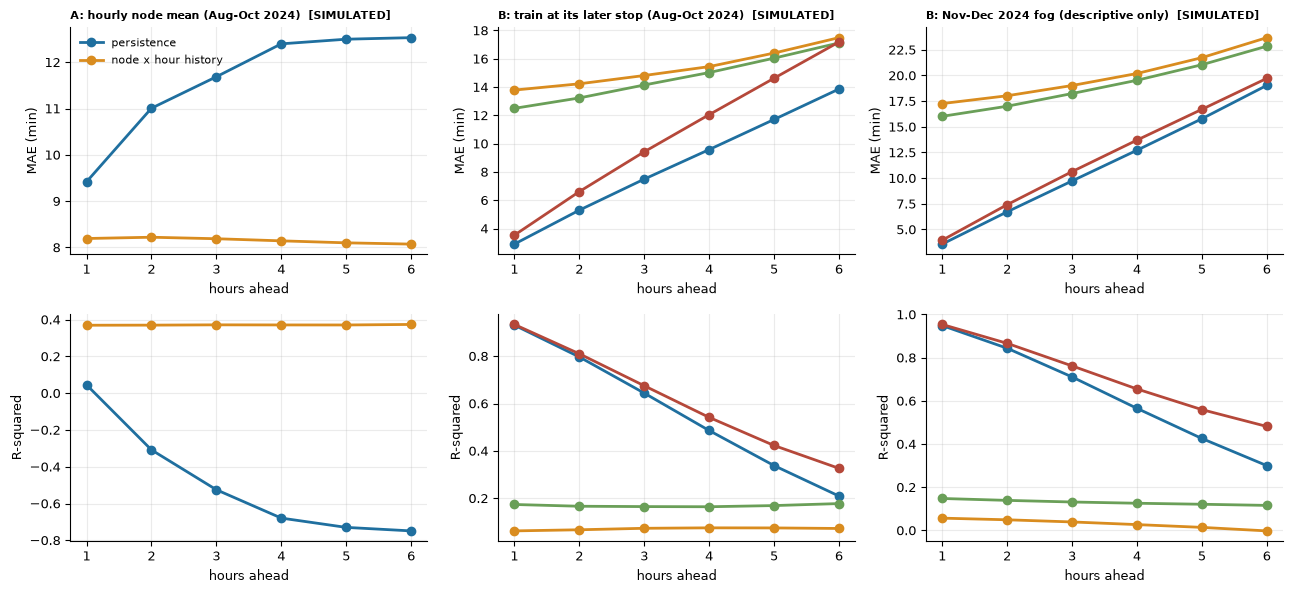

In [18]:
# descriptive only: the fog season of Nov-Dec 2024, scored with the same constants as above (history Jan-Jul 2024; nothing is fitted on the fog months)
fl, fh = "2024-11-01", "2024-12-31"
df_f, _, _, b_f = eda.load_window(fl, fh, tt=tt, nodes=nodes)
a_f = eda.arrivals(df_f, b_f); del df_f
# same constants as for Aug-Oct (history Jan-Jul 2024): nothing is fitted on the fog months
fog_rows, _ = eval_B(a_f, H_nh, H_tn, g_mean, b_f[0], None, "B train-level, Nov-Dec 2024 (descriptive, fog)", lin=lin_fit)
fogdf = pd.DataFrame(fog_rows)
print("Nov-Dec 2024: mean arrival delay %.1f min (decision window: %.1f); fog days %d" % (a_f.arrival_delay.mean(), a.arrival_delay.mean(), a_f[a_f.weather == "fog"].arr_date.nunique()))
print("MAE (min)"); print(fogdf.pivot(index="method", columns="h", values="MAE").round(2).to_string()); print("R2"); print(fogdf.pivot(index="method", columns="h", values="R2").round(3).to_string())
allb = pd.concat([base, fogdf])
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
views = [("A hourly node mean", "A: hourly node mean (Aug-Oct 2024)"), ("B train-level, Aug-Oct 2024", "B: train at its later stop (Aug-Oct 2024)"), ("B train-level, Nov-Dec 2024 (descriptive, fog)", "B: Nov-Dec 2024 fog (descriptive only)")]
cm = {"persistence": BLUE, "node x hour history": ORANGE, "train x node history": GREEN, "linear on current delay": RED}
for j, (v, ttl) in enumerate(views):
    for metric, row in (("MAE", 0), ("R2", 1)):
        ax = axes[row, j]
        for m_, c in cm.items():
            s = allb[(allb.view == v) & (allb.method == m_)]
            if len(s): ax.plot(s.h, s[metric], marker="o", color=c, lw=2, label=m_)
        ax.set_xlabel("hours ahead"); ax.set_ylabel("MAE (min)" if metric == "MAE" else "R-squared")
        if row == 0: ax.set_title(ttl + S, loc="left", fontweight="bold", fontsize=8)
axes[0, 0].legend(frameon=False, fontsize=8); plt.tight_layout(); save(fig, "15_baselines")

## Candidate features for later (summary, with the evidence above)

See `reports/phase4_findings.md` for the numbered findings and the artifact notes. In short, the evidence in section 6 ranks the predictors, and section 7 sets the bar the models must beat. No prediction table was built.